# Credit Approval Prediction
## A Boosting Project (Classification)

**Name:** Karthik Somaraju  
**Project Type:** Boosting (Classification) - Minor Project  
**Dataset:** Credit Approval Dataset  
**Source:** UCI Machine Learning Repository  
**Link:** https://archive.ics.uci.edu/dataset/27/credit+approval

## Problem Statement and Objective

Banks receive a lot of credit card applications and have to decide quickly whether each one should be **approved or rejected**. Approving a bad applicant means a financial loss, and rejecting a good applicant means losing a customer. A model that can help with this decision is useful.

**Objective:** Build boosting classification models (XGBoost, CatBoost, AdaBoost and LightGBM) to predict whether a credit card application is Approved (+) or Rejected (-) from the applicant attributes. Compare the models, pick the one with the highest test accuracy, tune it, and evaluate it with accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC.

**Task type:** Binary classification.

## Dataset Description

The Credit Approval dataset is taken from the UCI Machine Learning Repository (id = 27). It has 690 credit card applications with 15 input attributes (A1 to A15) and one target column (A16: + = approved, - = rejected).

The attribute names and values were changed to meaningless symbols by the data owners to protect the privacy of the applicants, so we do not know what each column exactly means (for example A9 or A10). The dataset has a mix of continuous columns, categorical columns and some missing values, which makes it good for practising data cleaning before modelling.

Note: the dataset is loaded directly from UCI using the `ucimlrepo` package, so no file upload is needed.

## 1. Installing the ucimlrepo library

In [1]:
pip install ucimlrepo

## 2. Fetching the dataset from UCI

In [2]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
credit_approval = fetch_ucirepo(id=27)

# data (as pandas dataframes)
X = credit_approval.data.features
y = credit_approval.data.targets

# metadata
print(credit_approval.metadata)

# variable information
print(credit_approval.variables)

{'uci_id': 27, 'name': 'Credit Approval', 'repository_url': 'https://archive.ics.uci.edu/dataset/27/credit+approval', 'data_url': 'https://archive.ics.uci.edu/static/public/27/data.csv', 'abstract': 'This data concerns credit card applications; good mix of attributes', 'area': 'Business', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 690, 'num_features': 15, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': [], 'target_col': ['A16'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1987, 'last_updated': 'Wed Aug 23 2023', 'dataset_doi': '10.24432/C5FS30', 'creators': ['J. R. Quinlan'], 'intro_paper': None, 'additional_info': {'summary': 'This file concerns credit card applications.  All attribute names and values have been changed to meaningless symbols to protect confidentiality of the data.\r\n  \r\nThis dataset is interesting because there is a good mix of attributes --

## 3. Importing the required libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

## 4. Combining features and target into one dataframe

In [4]:
df = pd.concat([X, y], axis = 1)
df.head()

,A15,A14,A13,A12,A11,A10,A9,A8,A7,A6,A5,A4,A3,A2,A1,A16
0,0,202.0,g,f,1,t,t,1.25,v,w,g,u,0.000,30.83,b,+
1,560,43.0,g,f,6,t,t,3.04,h,q,g,u,4.460,58.67,a,+
2,824,280.0,g,f,0,f,t,1.50,h,q,g,u,0.500,24.50,a,+
3,3,100.0,g,t,5,t,t,3.75,v,w,g,u,1.540,27.83,b,+
4,0,120.0,s,f,0,f,t,1.71,v,w,g,u,5.625,20.17,b,+


## 5. Checking the shape and data types

In [5]:
print("Shape of the dataset:", df.shape)
df.info()

Shape of the dataset: (690, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 16 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A15     690 non-null    int64  
 1   A14     677 non-null    float64
 2   A13     690 non-null    object 
 3   A12     690 non-null    object 
 4   A11     690 non-null    int64  
 5   A10     690 non-null    object 
 6   A9      690 non-null    object 
 7   A8      690 non-null    float64
 8   A7      681 non-null    object 
 9   A6      681 non-null    object 
 10  A5      684 non-null    object 
 11  A4      684 non-null    object 
 12  A3      690 non-null    float64
 13  A2      678 non-null    float64
 14  A1      678 non-null    object 
 15  A16     690 non-null    object 
dtypes: float64(4), int64(2), object(10)
memory usage: 86.4+ KB


**Understanding the data**

- **Rows:** each row is one credit card application.
- **Columns:** A1 to A15 are the applicant details (input features) and A16 is the target.
- **Target variable:** A16 (+ = Approved, - = Rejected).
- **Feature types:** some columns are numbers (continuous) and some are text categories (object type).

## 6. Statistical summary of the columns

In [6]:
print("Numeric columns:")
display(df.describe())

print("Categorical columns:")
display(df.describe(include = 'object'))

Numeric columns:


,A15,A14,A11,A8,A3,A2
count,690.000000,677.000000,690.00000,690.000000,690.000000,678.000000
mean,1017.385507,184.014771,2.40000,2.223406,4.758725,31.568171
std,5210.102598,173.806768,4.86294,3.346513,4.978163,11.957862
min,0.000000,0.000000,0.00000,0.000000,0.000000,13.750000
25%,0.000000,75.000000,0.00000,0.165000,1.000000,22.602500
50%,5.000000,160.000000,0.00000,1.000000,2.750000,28.460000
75%,395.500000,276.000000,3.00000,2.625000,7.207500,38.230000
max,100000.000000,2000.000000,67.00000,28.500000,28.000000,80.250000


Categorical columns:


,A13,A12,A10,A9,A7,A6,A5,A4,A1,A16
count,690,690,690,690,681,681,684,684,678,690
unique,3,2,2,2,9,14,3,3,2,2
top,g,f,f,t,v,c,g,u,b,-
freq,625,374,395,361,399,137,519,519,468,383


## 7. Checking the target variable

In [7]:
print(df['A16'].value_counts())
print()
print(df['A16'].value_counts(normalize = True) * 100)

A16
-    383
+    307
Name: count, dtype: int64

A16
-    55.507246
+    44.492754
Name: proportion, dtype: float64


## 8. Checking duplicate rows

In [8]:
rows_before = df.shape[0]
duplicates_before = df.duplicated().sum()
print("Duplicate rows:", duplicates_before)

Duplicate rows: 0


## 9. Checking missing values

In [9]:
missing_before = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df) * 100).round(2)

missing_table = pd.DataFrame({'Missing count': missing_before, 'Missing %': missing_percent})
missing_table[missing_table['Missing count'] > 0]

,Missing count,Missing %
A14,13,1.88
A7,9,1.30
A6,9,1.30
A5,6,0.87
A4,6,0.87
A2,12,1.74
A1,12,1.74


## 10. Checking unusual values in the categorical columns

In [10]:
for col in df.select_dtypes(include = 'object').columns:
    print(col, ":", df[col].unique())

A13 : ['g' 's' 'p']
A12 : ['f' 't']
A10 : ['t' 'f']
A9 : ['t' 'f']
A7 : ['v' 'h' 'bb' 'ff' 'j' 'z' nan 'o' 'dd' 'n']
A6 : ['w' 'q' 'm' 'r' 'cc' 'k' 'c' 'd' 'x' 'i' 'e' 'aa' 'ff' 'j' nan]
A5 : ['g' 'p' nan 'gg']
A4 : ['u' 'y' nan 'l']
A1 : ['b' 'a' nan]
A16 : ['+' '-']


**Data quality observations**

- The missing values are present only in a few columns, and each of those columns has only a small percentage missing, so no column needs to be dropped.
- The categorical columns only contain short codes (a, b, t, f etc.), with no extra spaces or spelling mistakes visible, so no text cleaning is needed.

## 11. Missing value treatment

In [11]:
# numeric columns -> median (not affected by outliers)
for col in df.select_dtypes(include = 'number').columns:
    df[col] = df[col].fillna(df[col].median())

# categorical columns -> mode (most frequent value)
for col in df.select_dtypes(include = 'object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])

## 12. Checking missing values again

In [12]:
print("Total missing values after treatment:", df.isnull().sum().sum())

Total missing values after treatment: 0


## 13. Outlier detection using boxplots

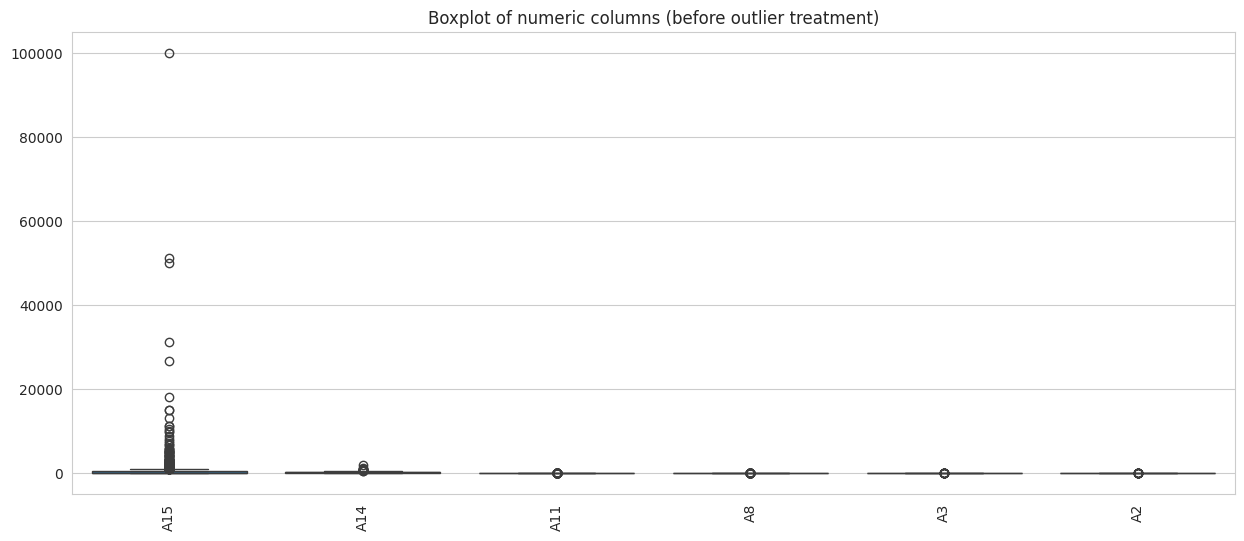

In [13]:
num_cols = df.select_dtypes(include = 'number').columns

plt.figure(figsize = (15, 6))
sns.boxplot(data = df[num_cols])
plt.title('Boxplot of numeric columns (before outlier treatment)')
plt.xticks(rotation = 90)
plt.show()

## 14. Counting outliers using the IQR method

In [14]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    count = ((df[col] < lower_limit) | (df[col] > upper_limit)).sum()
    print(f"Outliers in {col}: {count}")

Outliers in A15: 113
Outliers in A14: 13
Outliers in A11: 79
Outliers in A8: 63
Outliers in A3: 17
Outliers in A2: 18


**Decision on outliers:** the rows are not removed because the dataset is small (690 rows) and removing rows would waste data. Instead the outliers are **capped** to the IQR limits (values above the upper limit are set to the upper limit and values below the lower limit are set to the lower limit).

## 15. Outlier treatment (capping)

In [15]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    df[col] = np.where(df[col] > upper_limit, upper_limit, np.where(df[col] < lower_limit, lower_limit, df[col]))

## 16. Boxplot after outlier treatment

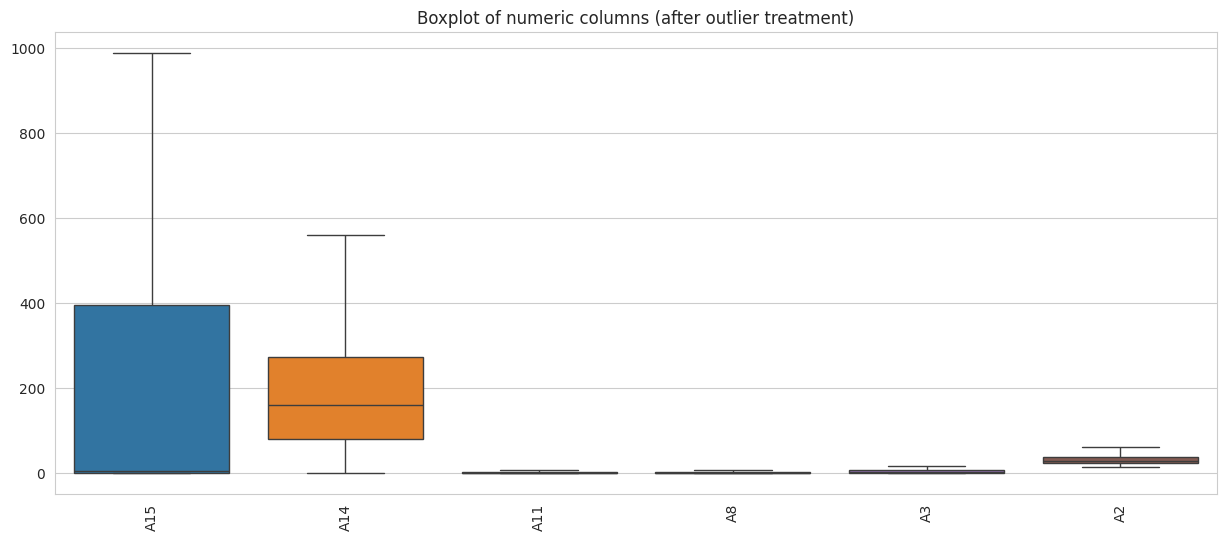

In [16]:
plt.figure(figsize = (15, 6))
sns.boxplot(data = df[num_cols])
plt.title('Boxplot of numeric columns (after outlier treatment)')
plt.xticks(rotation = 90)
plt.show()

## 17. Data cleaning summary

In [17]:
summary = pd.DataFrame({
    'Check': ['Rows', 'Columns', 'Duplicate rows', 'Total missing values', 'Columns with missing values'],
    'Before cleaning': [rows_before, 16, duplicates_before, int(missing_before.sum()), int((missing_before > 0).sum())],
    'After cleaning': [df.shape[0], df.shape[1], df.duplicated().sum(), int(df.isnull().sum().sum()), int((df.isnull().sum() > 0).sum())]
})
summary

,Check,Before cleaning,After cleaning
0,Rows,690,690
1,Columns,16,16
2,Duplicate rows,0,0
3,Total missing values,67,0
4,Columns with missing values,7,0


**Cleaning decisions (in my own words)**

1. Duplicates were checked and the count is shown above - no row had to be dropped unless the count was more than 0.
2. Missing numeric values were filled with the **median** and missing categorical values with the **mode**, because only a few values were missing and the dataset is small, so dropping rows was a waste.
3. Outliers were **capped using IQR** instead of removing rows.
4. Categorical columns will be converted to numbers using one-hot encoding (get_dummies) before modelling.
5. Feature scaling is skipped because boosting models are made of decision trees, which only compare a feature with a threshold.

## 18. Visualization 1 - Distribution of the target (A16)

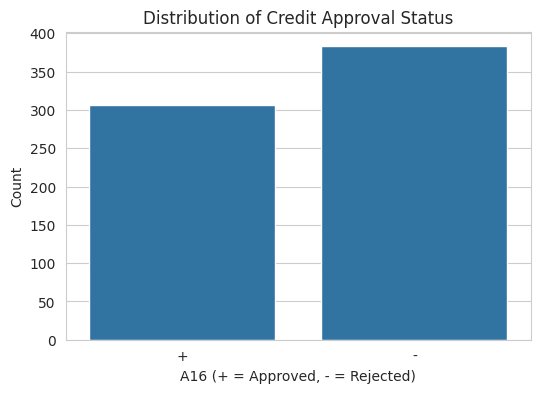

In [18]:
plt.figure(figsize = (6, 4))
sns.countplot(x = 'A16', data = df)
plt.title('Distribution of Credit Approval Status')
plt.xlabel('A16 (+ = Approved, - = Rejected)')
plt.ylabel('Count')
plt.show()

**Observation:** the two classes are fairly close to each other (roughly 44% approved and 56% rejected), so there is only a small class imbalance. SMOTE will still be used on the training data, as done in class, so that the models see both classes equally.

## 19. Visualization 2 - Distribution of numeric columns

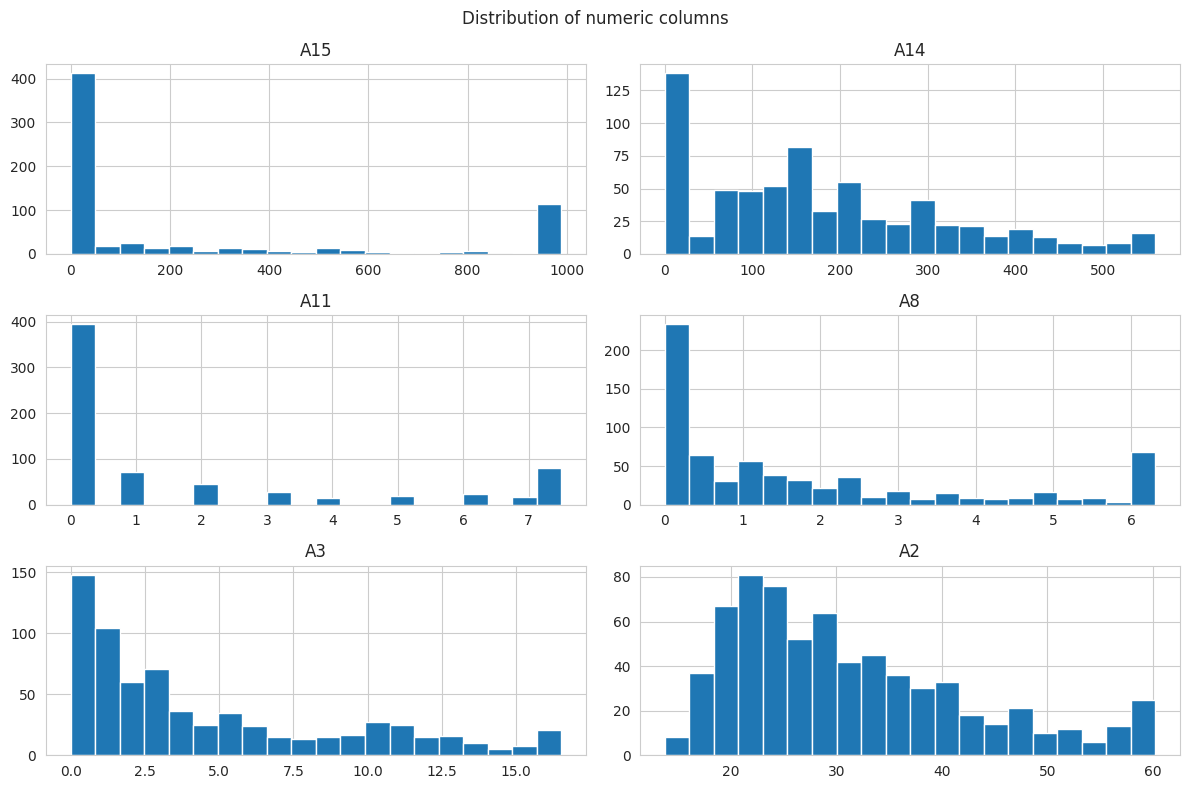

In [19]:
df[num_cols].hist(figsize = (12, 8), bins = 20)
plt.suptitle('Distribution of numeric columns')
plt.tight_layout()
plt.show()

**Observation:** most of the numeric columns are right-skewed, meaning most applicants have small values and a few have large values. This is the reason the outliers were capped. Because boosting uses trees, the skewness is not a big problem for the models.

## 20. Visualization 3 - Categorical columns vs approval status

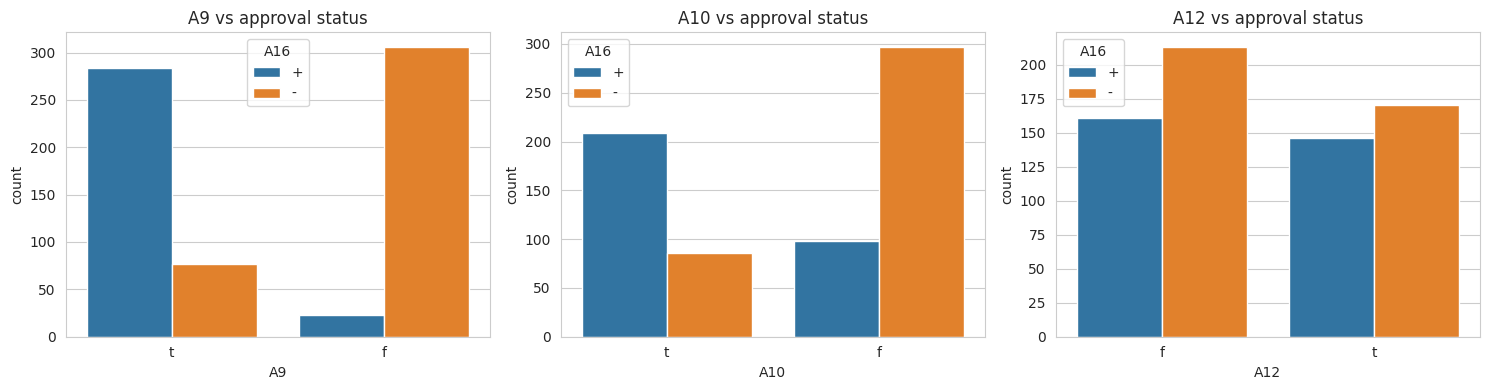

In [20]:
fig, axes = plt.subplots(1, 3, figsize = (15, 4))
for ax, col in zip(axes, ['A9', 'A10', 'A12']):
    sns.countplot(x = col, hue = 'A16', data = df, ax = ax)
    ax.set_title(col + ' vs approval status')
plt.tight_layout()
plt.show()

**Observation:** for the column A9 the two groups behave very differently - applicants in one group are mostly approved and the others are mostly rejected, so A9 looks like a very useful feature. A10 shows a smaller difference and A12 shows almost no difference between approved and rejected.

## 21. Visualization 4 - Numeric columns vs approval status

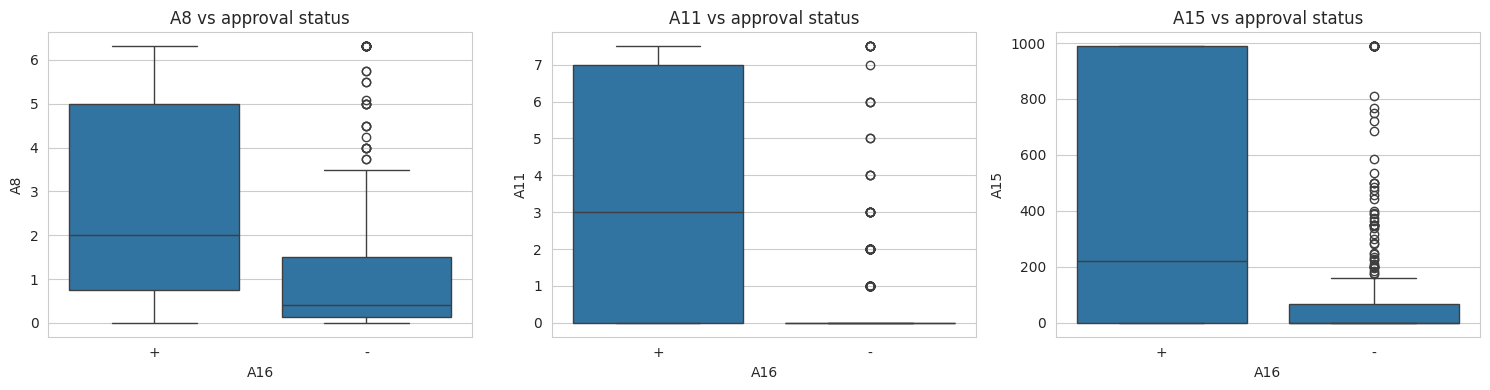

In [21]:
fig, axes = plt.subplots(1, 3, figsize = (15, 4))
for ax, col in zip(axes, ['A8', 'A11', 'A15']):
    sns.boxplot(x = 'A16', y = col, data = df, ax = ax)
    ax.set_title(col + ' vs approval status')
plt.tight_layout()
plt.show()

**Observation:** for A8, A11 and A15 the approved applicants (+) generally have higher values than the rejected ones (-). So these columns carry useful information for the model.

## 22. Encoding the target variable

In [22]:
df['A16'] = df['A16'].map({'+': 1, '-': 0})
print(df['A16'].value_counts())

A16
0    383
1    307
Name: count, dtype: int64


## 23. Encoding the categorical columns (get_dummies)

In [23]:
print(df.select_dtypes(include = 'object').columns)

df = pd.get_dummies(df, drop_first = True, dtype = int)
df.info()

Index(['A13', 'A12', 'A10', 'A9', 'A7', 'A6', 'A5', 'A4', 'A1'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 690 entries, 0 to 689
Data columns (total 38 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   A15     690 non-null    float64
 1   A14     690 non-null    float64
 2   A11     690 non-null    float64
 3   A8      690 non-null    float64
 4   A3      690 non-null    float64
 5   A2      690 non-null    float64
 6   A16     690 non-null    int64  
 7   A13_p   690 non-null    int64  
 8   A13_s   690 non-null    int64  
 9   A12_t   690 non-null    int64  
 10  A10_t   690 non-null    int64  
 11  A9_t    690 non-null    int64  
 12  A7_dd   690 non-null    int64  
 13  A7_ff   690 non-null    int64  
 14  A7_h    690 non-null    int64  
 15  A7_j    690 non-null    int64  
 16  A7_n    690 non-null    int64  
 17  A7_o    690 non-null    int64  
 18  A7_v    690 non-null    int64  
 19  A7_z    690 non-null    int64  


## 24. Visualization 5 - Correlation of features with the target

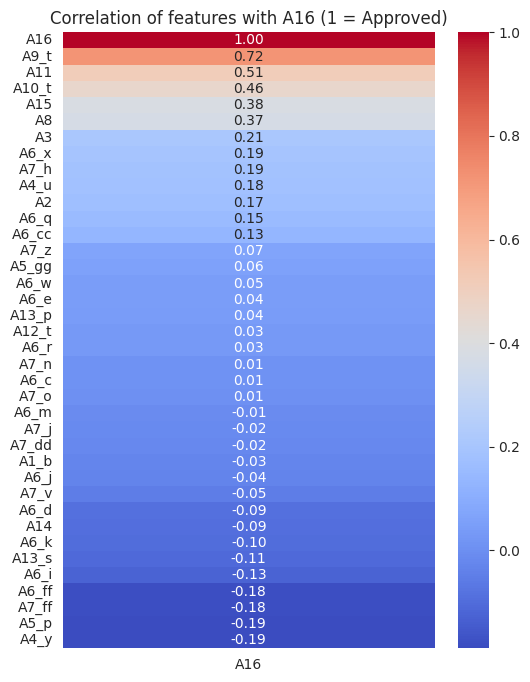

In [24]:
plt.figure(figsize = (6, 8))
corr = df.corr()[['A16']].sort_values(by = 'A16', ascending = False)
sns.heatmap(corr, annot = True, cmap = 'coolwarm', fmt = '.2f')
plt.title('Correlation of features with A16 (1 = Approved)')
plt.show()

**Observation:** the feature with the highest correlation with the target is the one from A9 (the column A9_t after encoding). Most of the other features have a small correlation, so the model has to combine several features to get a good prediction.

## 25. Splitting the data into features and target

In [25]:
from sklearn.model_selection import train_test_split

x = df.drop('A16', axis = 1)
y = df['A16'].astype(int)

print(y.value_counts(dropna = False))
print("Null values in target:", y.isna().sum())

A16
0    383
1    307
Name: count, dtype: int64
Null values in target: 0


## 26. Train test split (80:20)

In [26]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (552, 37)
X_test: (138, 37)
y_train: (552,)
y_test: (138,)


## 27. Installing imbalanced-learn

In [27]:
!pip install imbalanced-learn

## 28. Applying SMOTE on the training data only

In [28]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state = 42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

## 29. Class counts before and after SMOTE

In [29]:
print("Before SMOTE:")
print(y_train.value_counts())
print()
print("After SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
A16
0    315
1    237
Name: count, dtype: int64

After SMOTE:
A16
0    315
1    315
Name: count, dtype: int64


**Note:** SMOTE was applied only after the split and only on the training data, so the test set stays untouched and the test results are honest.

## Choosing the approach

The task is **binary classification** (Approved = 1, Rejected = 0). I am using **boosting** algorithms because they build many small trees one after another, where each new tree tries to fix the mistakes of the previous trees. This usually gives better accuracy than a single decision tree. The four boosting models that will be compared are XGBoost, CatBoost, AdaBoost and LightGBM.

## 30. Importing the evaluation metrics and creating a results dictionary

In [30]:
from sklearn.metrics import classification_report, accuracy_score

results = {}

## 31. Installing XGBoost

In [31]:
!pip install xgboost

## 32. Model 1 - XGBoost (default parameters)

In [32]:
from xgboost import XGBClassifier

model_xgb = XGBClassifier(random_state = 42)
model_xgb.fit(X_train_smote, y_train_smote)

y_pred = model_xgb.predict(X_test)
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
results['XGBoost'] = accuracy_score(y_test, y_pred)

              precision    recall  f1-score   support

           0       0.76      0.85      0.81        68
           1       0.84      0.74      0.79        70

    accuracy                           0.80       138
   macro avg       0.80      0.80      0.80       138
weighted avg       0.80      0.80      0.80       138

Accuracy: 0.7971014492753623


## 33. Installing CatBoost

In [33]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 5.7 MB/s eta 0:00:00


## 34. Model 2 - CatBoost (default parameters)

In [34]:
from catboost import CatBoostClassifier

model_cat = CatBoostClassifier(verbose = 0, random_seed = 42)
model_cat.fit(X_train_smote, y_train_smote)

y_pred = model_cat.predict(X_test)
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
results['CatBoost'] = accuracy_score(y_test, y_pred)

              precision    recall  f1-score   support

           0       0.82      0.87      0.84        68
           1       0.86      0.81      0.84        70

    accuracy                           0.84       138
   macro avg       0.84      0.84      0.84       138
weighted avg       0.84      0.84      0.84       138

Accuracy: 0.8405797101449275


## 35. Model 3 - AdaBoost (decision stump as the weak learner)

In [35]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

model_ada = AdaBoostClassifier(
    estimator = DecisionTreeClassifier(max_depth = 1),
    n_estimators = 50,
    learning_rate = 1.0,
    random_state = 42
)
model_ada.fit(X_train_smote, y_train_smote)

y_pred = model_ada.predict(X_test)
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
results['AdaBoost'] = accuracy_score(y_test, y_pred)

              precision    recall  f1-score   support

           0       0.81      0.81      0.81        68
           1       0.81      0.81      0.81        70

    accuracy                           0.81       138
   macro avg       0.81      0.81      0.81       138
weighted avg       0.81      0.81      0.81       138

Accuracy: 0.8115942028985508


## 36. Installing LightGBM

In [37]:
!pip install lightgbm

## 37. Model 4 - LightGBM (default parameters)

In [38]:
from lightgbm import LGBMClassifier

model_lgb = LGBMClassifier(random_state = 42, verbose = -1)
model_lgb.fit(X_train_smote, y_train_smote)

y_pred = model_lgb.predict(X_test)
print(classification_report(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
results['LightGBM'] = accuracy_score(y_test, y_pred)

              precision    recall  f1-score   support

           0       0.78      0.87      0.82        68
           1       0.85      0.76      0.80        70

    accuracy                           0.81       138
   macro avg       0.82      0.81      0.81       138
weighted avg       0.82      0.81      0.81       138

Accuracy: 0.8115942028985508


## 38. Comparing all the boosting models

,Model,Test Accuracy
0,CatBoost,0.840580
1,AdaBoost,0.811594
2,LightGBM,0.811594
3,XGBoost,0.797101


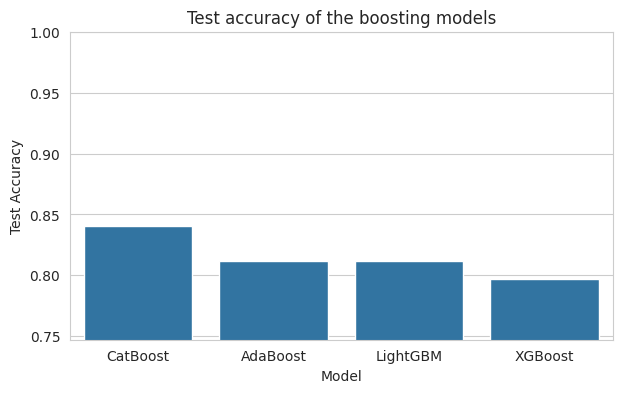

Model with the highest accuracy: CatBoost


In [39]:
comparison = pd.DataFrame({'Model': list(results.keys()), 'Test Accuracy': list(results.values())})
comparison = comparison.sort_values(by = 'Test Accuracy', ascending = False).reset_index(drop = True)
display(comparison)

plt.figure(figsize = (7, 4))
sns.barplot(x = 'Model', y = 'Test Accuracy', data = comparison)
plt.ylim(comparison['Test Accuracy'].min() - 0.05, 1.0)
plt.title('Test accuracy of the boosting models')
plt.show()

best_name = comparison.loc[0, 'Model']
print("Model with the highest accuracy:", best_name)

**Observation:** the model at the top of the table has the highest test accuracy, so it is taken forward for hyperparameter tuning and the final evaluation. The other models are only used for comparison.

## 39. Hyperparameter tuning of the best model

In [40]:
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

# one tuned version for each algorithm, only the best one is used
tuned_models = {
    'XGBoost': XGBClassifier(n_estimators = 200, learning_rate = 0.05, max_depth = 4, random_state = 42),
    'CatBoost': CatBoostClassifier(iterations = 200, depth = 6, learning_rate = 0.1, verbose = 0, random_seed = 42),
    'AdaBoost': AdaBoostClassifier(estimator = DecisionTreeClassifier(max_depth = 2), n_estimators = 200, learning_rate = 0.5, random_state = 42),
    'LightGBM': LGBMClassifier(n_estimators = 200, learning_rate = 0.05, num_leaves = 15, random_state = 42, verbose = -1)
}

default_models = {'XGBoost': model_xgb, 'CatBoost': model_cat, 'AdaBoost': model_ada, 'LightGBM': model_lgb}

tuned_model = tuned_models[best_name]
tuned_model.fit(X_train_smote, y_train_smote)

y_pred_tuned = tuned_model.predict(X_test)
tuned_acc = accuracy_score(y_test, y_pred_tuned)

print(best_name, "default accuracy:", round(results[best_name], 4))
print(best_name, "tuned accuracy  :", round(tuned_acc, 4))

CatBoost default accuracy: 0.8406
CatBoost tuned accuracy  : 0.8333


## 40. Selecting the final model

In [41]:
# keep whichever version (default or tuned) gives the higher test accuracy
if tuned_acc >= results[best_name]:
    final_model = tuned_model
    final_version = 'tuned'
    final_acc = tuned_acc
else:
    final_model = default_models[best_name]
    final_version = 'default'
    final_acc = results[best_name]

print("Final model:", best_name, "(" + final_version + " parameters)")
print("Final test accuracy:", round(final_acc, 4))

Final model: CatBoost (default parameters)
Final test accuracy: 0.8406


**Note:** tuning does not always improve the result on a small test set. So the version (default or tuned) with the higher accuracy is kept as the final model.

## 41. Final model evaluation - metrics

In [42]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

y_pred_final = final_model.predict(X_test)
y_prob_final = final_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred_final), 4))
print("Precision:", round(precision_score(y_test, y_pred_final), 4))
print("Recall   :", round(recall_score(y_test, y_pred_final), 4))
print("F1-score :", round(f1_score(y_test, y_pred_final), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_final), 4))
print()
print(classification_report(y_test, y_pred_final, target_names = ['Rejected (0)', 'Approved (1)']))

Accuracy : 0.8406
Precision: 0.8636
Recall   : 0.8143
F1-score : 0.8382
ROC-AUC  : 0.9074

              precision    recall  f1-score   support

Rejected (0)       0.82      0.87      0.84        68
Approved (1)       0.86      0.81      0.84        70

    accuracy                           0.84       138
   macro avg       0.84      0.84      0.84       138
weighted avg       0.84      0.84      0.84       138



**What the metrics mean (simple language)**

- **Accuracy:** out of all test applications, the share predicted correctly.
- **Precision:** when the model says "Approved", how often it is right.
- **Recall:** out of all the applications that were really Approved, how many the model found.
- **F1-score:** a single score that is high only when precision and recall are both high.
- **ROC-AUC:** how well the model separates approved from rejected applications (0.5 is a random guess and 1.0 is perfect).

## 42. Confusion matrix

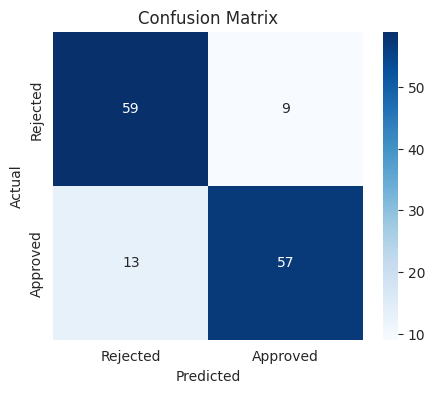

True negatives (Rejected predicted Rejected): 59
False positives (Rejected predicted Approved): 9
False negatives (Approved predicted Rejected): 13
True positives (Approved predicted Approved): 57


In [43]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize = (5, 4))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues',
            xticklabels = ['Rejected', 'Approved'], yticklabels = ['Rejected', 'Approved'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

tn, fp, fn, tp = cm.ravel()
print("True negatives (Rejected predicted Rejected):", tn)
print("False positives (Rejected predicted Approved):", fp)
print("False negatives (Approved predicted Rejected):", fn)
print("True positives (Approved predicted Approved):", tp)

**Observation:** the false positives are the costly mistakes for a bank because a bad application gets approved. The false negatives mean a good applicant was rejected.

## 43. ROC curve

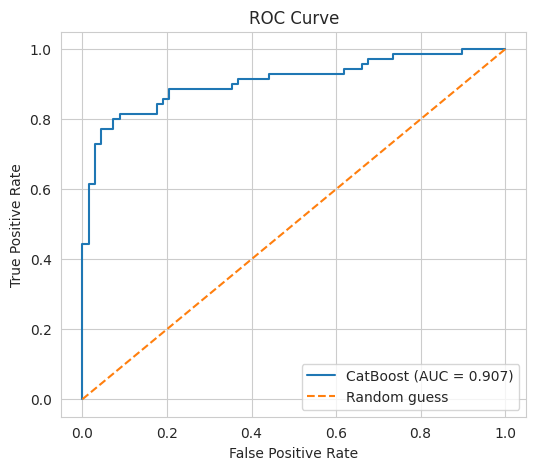

In [44]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob_final)
auc = roc_auc_score(y_test, y_prob_final)

plt.figure(figsize = (6, 5))
plt.plot(fpr, tpr, label = f'{best_name} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], '--', label = 'Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

## 44. Feature importance

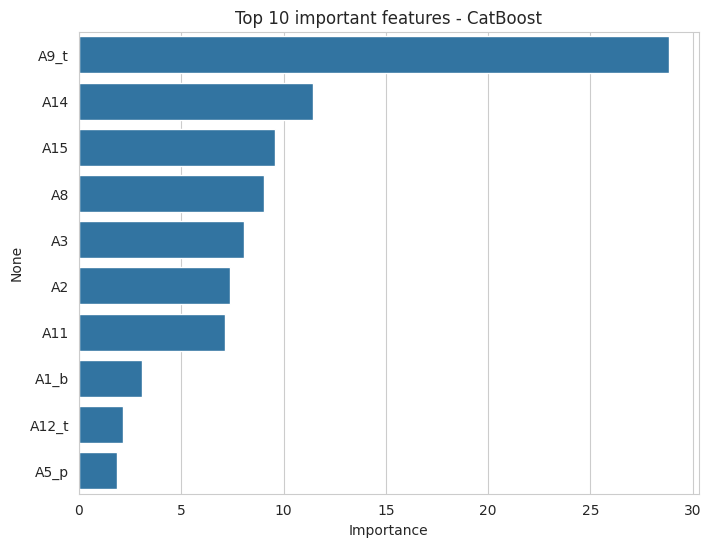

A9_t     28.855903
A14      11.424370
A15       9.586863
A8        9.044185
A3        8.090425
A2        7.403845
A11       7.156671
A1_b      3.088364
A12_t     2.168332
A5_p      1.864268
dtype: float64


In [45]:
importances = pd.Series(final_model.feature_importances_, index = X_train_smote.columns).sort_values(ascending = False)

plt.figure(figsize = (8, 6))
sns.barplot(x = importances.values[:10], y = importances.index[:10])
plt.title('Top 10 important features - ' + best_name)
plt.xlabel('Importance')
plt.show()

print(importances.head(10))

## 45. Real time testing on one new applicant

In [46]:
new_applicant = X_test.iloc[[0]]
prediction = final_model.predict(new_applicant)

print("Predicted:", "Approved" if prediction[0] == 1 else "Rejected")
print("Actual   :", "Approved" if y_test.iloc[0] == 1 else "Rejected")

Predicted: Rejected
Actual   : Rejected


## 46. Final summary

In [47]:
print("Dataset            : Credit Approval (UCI, id = 27)")
print("Rows / Columns     :", df.shape[0], "/", df.shape[1])
print("Models compared    :", ", ".join(results.keys()))
print("Best model         :", best_name, "(" + final_version + " parameters)")
print("Test accuracy      :", round(accuracy_score(y_test, y_pred_final), 4))
print("Precision / Recall :", round(precision_score(y_test, y_pred_final), 4), "/", round(recall_score(y_test, y_pred_final), 4))
print("F1-score / ROC-AUC :", round(f1_score(y_test, y_pred_final), 4), "/", round(roc_auc_score(y_test, y_prob_final), 4))

Dataset            : Credit Approval (UCI, id = 27)
Rows / Columns     : 690 / 38
Models compared    : XGBoost, CatBoost, AdaBoost, LightGBM
Best model         : CatBoost (default parameters)
Test accuracy      : 0.8406
Precision / Recall : 0.8636 / 0.8143
F1-score / ROC-AUC : 0.8382 / 0.9074


## Key Findings, Limitations and Conclusion

**Key findings**

- Best model: CatBoost with test accuracy: 84.06%.

**Limitations**

- Only 690 rows, so a single 20% test set is small and the scores can change with a different split.
- Column names are hidden, so the results cannot be explained in real-world terms.
- Missing values and outliers were treated before the train/test split, which is simple but lets a little information from the test rows reach the training step.

